In [83]:
from scripts.read_field import read_dir
from scripts.mm.experiment import Experiment
import os 
import numpy as np 
from typing import Literal
from scripts.scientific import apply
import matplotlib.pyplot as plt
apply()

In [229]:
path = os.path.join("./01-repulsion/skyrmion_system")
runs = sorted([os.path.join(path, d) for d in os.listdir(path) if d.startswith("drive-")])[5:]
data = [read_dir(run) for run in runs]
experiments = [Experiment.load(run) for run in runs]

In [230]:
def trajectory(data, experiment: Experiment, method: Literal['center', 'charge'] = 'center'):
    xs = np.array([])
    ys = np.array([])
    W = experiment.width / experiment.dx
    H = experiment.height / experiment.dx
    X, Y = np.meshgrid(np.arange(-W, W) * experiment.dx, -np.arange(-H, H) * experiment.dx)
    for i in range(len(data)):
        if method == 'center':
            weight = (1- data[i,:,:,2]) ** 2
        if method == 'charge':
            weight = np.sum(data[i] * np.linalg.cross(np.gradient(data[i], axis=0), np.gradient(data[i], axis=1)), axis=2)
        norm = np.sum(weight)

        x = np.sum(weight * X) / norm
        y = np.sum(weight * Y) / norm
        xs = np.append(xs, x)
        ys = np.append(ys, y)
    return xs, ys

[np.float64(-0.012500000000000356), np.float64(-0.1267016367729775), np.float64(-0.05620570101109583), np.float64(-0.11062471964532877), np.float64(-0.037522226106521055), np.float64(-0.07903128958507703), np.float64(-0.05821275951607932), np.float64(-0.0613420343081256), np.float64(-0.04133401336674769), np.float64(-0.04035431817564848), np.float64(-0.02483871246063552), np.float64(-0.014336195773174087), np.float64(0.0005049382660993594), np.float64(0.01865137124607281), np.float64(0.0368788555017257), np.float64(0.05680559313006767), np.float64(0.07623108502375336), np.float64(0.10164981667033599), np.float64(0.12524831137059927), np.float64(0.15243943219723102), np.float64(0.17906759095462788), np.float64(0.16656759095462753), np.float64(0.10139188195502523), np.float64(0.19821619883956215), np.float64(0.18435943543341898), np.float64(0.2764131727969509), np.float64(0.280530173924302), np.float64(0.32909356643841625), np.float64(0.36071381401235814), np.float64(0.39593634303167036)

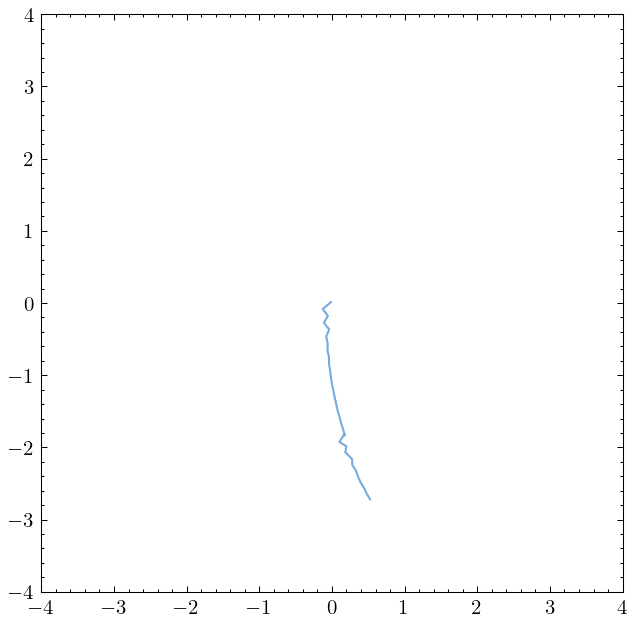

In [231]:
ts = [trajectory(d, e, method='charge') for d, e in zip(data, experiments)]
xs, ys = [], []
curr = [np.float64(0), np.float64(0)]

for t in ts:
    xs = [*xs, *(t[0] + curr[0])]
    ys = [*ys, *(t[1] + curr[1])]
    curr[0] = xs[-1]
    curr[1] = ys[-1]

plt.subplots(figsize=(5,5))
plt.plot(xs, ys)
plt.xlim([-4,4])
plt.ylim([-4,4])

print(xs, ys)

array([-0.0125    , -0.12670164, -0.0562057 , -0.11062472, -0.03752223,
       -0.07903129, -0.05821276, -0.06134203, -0.04133401, -0.04035432,
       -0.02483871, -0.0143362 ,  0.00050494,  0.01865137,  0.03687886,
        0.05680559,  0.07623109,  0.10164982,  0.12524831,  0.15243943,
        0.17906759])

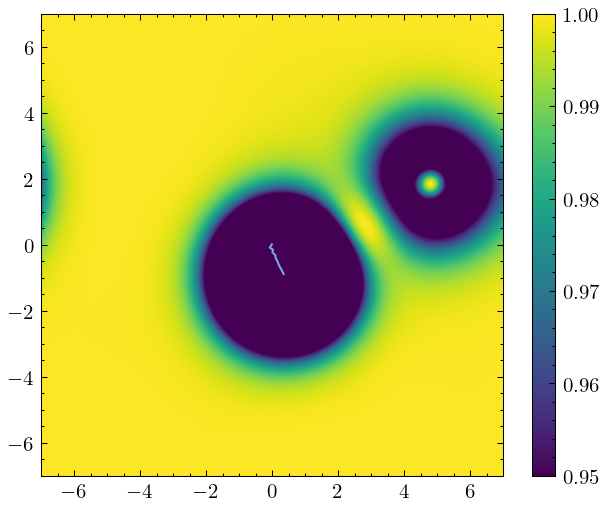

In [250]:
plt.imshow(data[1][11,:,:,2], extent=([-7, 7, -7, 7]), vmin=0.95, vmax=1)
plt.colorbar()
plt.plot(*ts[1])
ts[0][0]